# Notebook 07 — Risk Framework & Validation

> **SYNTHETIC DATA NOTICE:** All data is computer-generated. Findings describe only this simulated dataset.

**Business question answered:**
- **Q11:** Can we identify high-risk customer groups?

**Evidence source:** `sql/09_high_value_churn.sql`

**Methodology:**
- Rule-based risk score (0–3) using 3 leading indicators
- Validation: churn rate MUST increase monotonically with risk score (else framework is uninformative)
- Time-based validation note: in a real project, thresholds would be set on earlier months and evaluated on later months. Here we validate on the full dataset given the synthetic nature.

**Caution:** This is a descriptive risk framework, not a trained predictive model.

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import numpy as np
from pathlib import Path

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 120
FIGURES_DIR = Path('../outputs/figures')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR = Path('../outputs/tables')
TABLES_DIR.mkdir(parents=True, exist_ok=True)

conn = sqlite3.connect('../db/churn.db')
print('Connected.')

Connected.


## 1. Risk Tier Validation

In [2]:
df_val = pd.read_sql('SELECT * FROM risk_tier_validation ORDER BY risk_score DESC', conn)
print('Risk Tier Validation (key: churn_pct should increase monotonically with risk_score)')
print(df_val.to_string(index=False))

# Monotonicity check
sorted_pcts = df_val.sort_values('risk_score')['churn_pct'].tolist()
is_monotone = all(sorted_pcts[i] <= sorted_pcts[i+1] for i in range(len(sorted_pcts)-1))
print()
print(f'✓ Monotonic increase: {is_monotone}')
if not is_monotone:
    print('⚠️  WARNING: Framework is NOT monotone. Risk flags may not be sufficiently predictive.')
    print('Consider reviewing flag thresholds or segment sizes (n < 200 = unreliable).')

Risk Tier Validation (key: churn_pct should increase monotonically with risk_score)
risk_tier  risk_score  total_customers  churned  churn_pct  wilson_lower  wilson_upper
     High           2               17       12      70.59         48.93         92.25
   Medium           1              396       97      24.49         20.26         28.73
      Low           0             1836      203      11.06          9.62         12.49

✓ Monotonic increase: True


<cell>:26: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


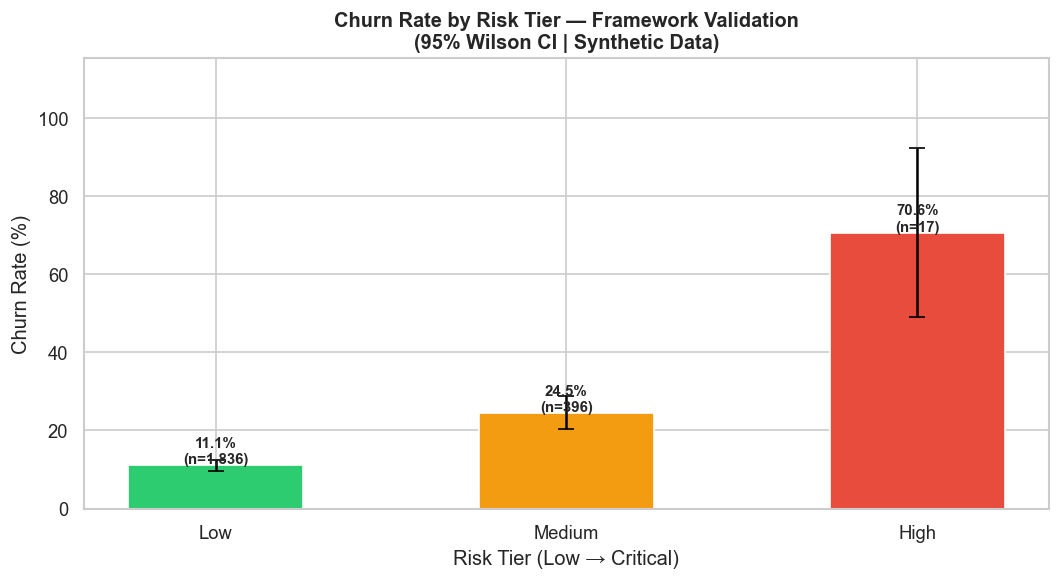

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))

tier_order = df_val.sort_values('risk_score')['risk_tier'].tolist()
churn_vals = df_val.sort_values('risk_score')['churn_pct'].tolist()
ci_lo = df_val.sort_values('risk_score')['wilson_lower'].tolist()
ci_hi = df_val.sort_values('risk_score')['wilson_upper'].tolist()
n_vals = df_val.sort_values('risk_score')['total_customers'].tolist()

colors = ['#2ecc71', '#f39c12', '#e74c3c', '#8e44ad']
bars = ax.bar(tier_order, churn_vals, color=colors[:len(tier_order)], edgecolor='white', width=0.5)
ax.errorbar(tier_order, churn_vals,
            yerr=[np.array(churn_vals) - np.array(ci_lo), np.array(ci_hi) - np.array(churn_vals)],
            fmt='none', color='black', capsize=5)

for bar, val, n in zip(bars, churn_vals, n_vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{val:.1f}%\n(n={n:,})', ha='center', fontsize=9, fontweight='bold')

ax.set_title('Churn Rate by Risk Tier — Framework Validation\n(95% Wilson CI | Synthetic Data)', fontsize=12, fontweight='bold')
ax.set_xlabel('Risk Tier (Low → Critical)')
ax.set_ylabel('Churn Rate (%)')
ax.set_ylim(0, max(ci_hi) * 1.25 if ci_hi else 100)

plt.tight_layout()
plt.savefig(FIGURES_DIR / '07_risk_tier_validation.png', bbox_inches='tight')
plt.show()

## 2. High-Risk Active Customers (Revenue at Risk — Q9/Q11)

In [4]:
df_high = pd.read_sql('SELECT * FROM high_risk_active_customers ORDER BY mrr DESC', conn)
print(f'High/Critical risk active customers: {len(df_high):,}')
print(f'Total MRR at risk: ₹{df_high["mrr"].sum():,.0f}')
print()
print('Top 10 by MRR:')
print(df_high[['customer_id','plan','mrr','risk_tier','flag_inactive','flag_support_friction','flag_low_stickiness']].head(10).to_string(index=False))

High/Critical risk active customers: 5
Total MRR at risk: ₹10,985

Top 10 by MRR:
                         customer_id    plan     mrr risk_tier  flag_inactive  flag_support_friction  flag_low_stickiness
306504fa-8e02-4f77-8269-0b339700f7ff   Scale 3999.00      High              1                      0                    1
5580b1c8-75ff-421e-95b5-f2db99f91657   Scale 3999.00      High              0                      1                    1
58d978a9-3341-49a2-9c55-d1d48808005b  Growth 1244.17      High              0                      1                    1
1da8aba1-fe6a-4402-9da8-e7073caceb0b  Growth 1244.17      High              0                      1                    1
adea25c2-31ba-4bfc-b96f-edcea5a8e164 Starter  499.00      High              0                      1                    1


risk_tier  risk_score  total_mrr  customers
     High           2   10985.34          5
   Medium           1  361864.26        299
      Low           0 2002819.55       1633


<cell>:31: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


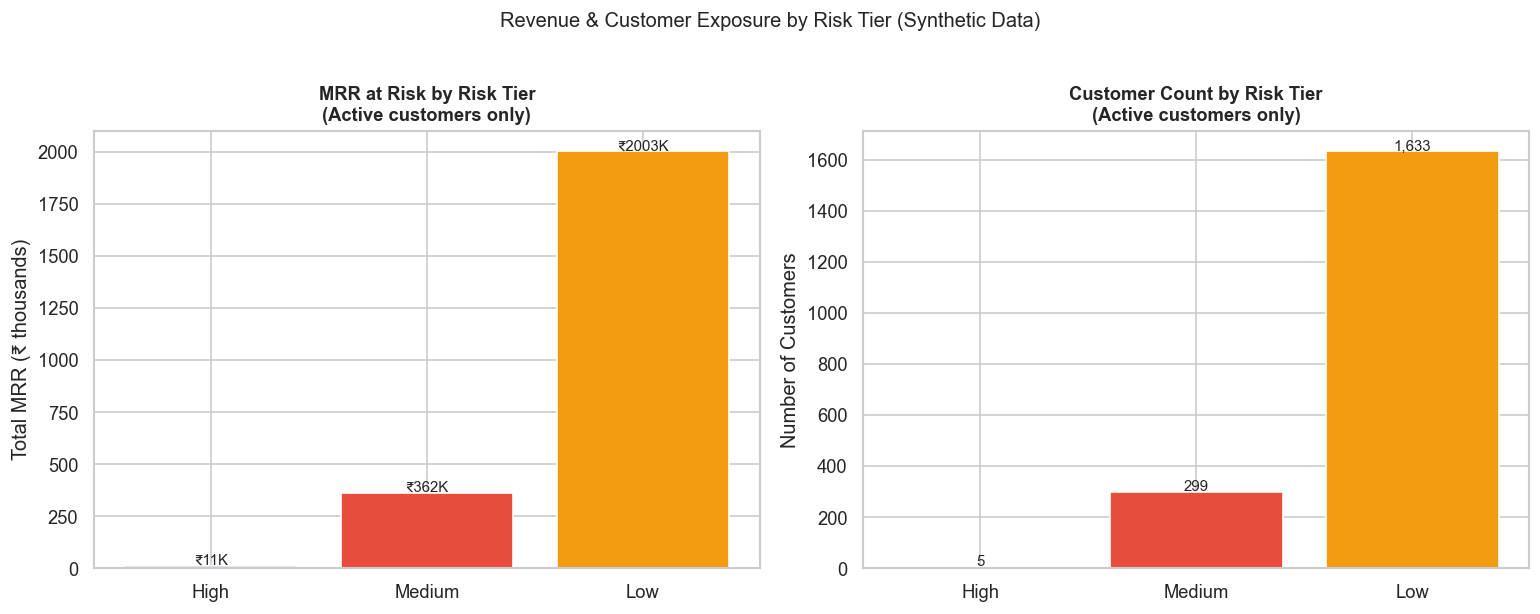

In [5]:
# Revenue at risk by tier
df_rev_tier = pd.read_sql("""
    SELECT risk_tier, risk_score, SUM(total_mrr_at_risk) as total_mrr, SUM(customer_count) as customers
    FROM revenue_at_risk_by_tier
    GROUP BY risk_tier, risk_score
    ORDER BY risk_score DESC
""", conn)
print(df_rev_tier.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

colors = ['#8e44ad', '#e74c3c', '#f39c12', '#2ecc71']

# Left: MRR at risk
axes[0].bar(df_rev_tier['risk_tier'], df_rev_tier['total_mrr'] / 1000, color=colors[:len(df_rev_tier)], edgecolor='white')
axes[0].set_title('MRR at Risk by Risk Tier\n(Active customers only)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Total MRR (₹ thousands)')
for i, (_, row) in enumerate(df_rev_tier.iterrows()):
    axes[0].text(i, row['total_mrr']/1000 + 5, f'₹{row["total_mrr"]/1000:.0f}K', ha='center', fontsize=9)

# Right: Customer count
axes[1].bar(df_rev_tier['risk_tier'], df_rev_tier['customers'], color=colors[:len(df_rev_tier)], edgecolor='white')
axes[1].set_title('Customer Count by Risk Tier\n(Active customers only)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Number of Customers')
for i, (_, row) in enumerate(df_rev_tier.iterrows()):
    axes[1].text(i, row['customers'] + 5, f'{row["customers"]:,}', ha='center', fontsize=9)

plt.suptitle('Revenue & Customer Exposure by Risk Tier (Synthetic Data)', fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '07_revenue_at_risk_by_tier.png', bbox_inches='tight')
plt.show()

## 3. Save Customer Risk List for Power BI

In [6]:
df_all_risk = pd.read_sql('SELECT * FROM customer_risk_scores WHERE is_churned = 0', conn)
df_all_risk.to_csv(TABLES_DIR / '07_active_customer_risk_scores.csv', index=False)
print(f'Saved risk scores for {len(df_all_risk):,} active customers.')
print(f'File: {TABLES_DIR}/07_active_customer_risk_scores.csv')

Saved risk scores for 1,937 active customers.
File: ..\outputs\tables/07_active_customer_risk_scores.csv


In [7]:
conn.close()